# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

#### Sandi Suryo Nugroho
### 5054251020

**Dataset:** https://www.kaggle.com/mlg-ulb/creditcardfraud

**Tujuan:** Membangun model klasifikasi dengan ensemble method (Random Forest) dan menangani class imbalance menggunakan SMOTE.

## Import

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc

from imblearn.over_sampling import SMOTE

## Load Dataset

In [3]:
df = pd.read_csv('creditcard.csv')

display(df.head())
print(f"Dimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Dimensi dataset: 284807 baris, 31 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20    

## EDA 

Jumlah data per kelas:
Class
0    284315
1       492
Name: count, dtype: int64

Persentase data per kelas:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


C:\Users\Axioo Pongo\AppData\Local\Temp\ipykernel_15736\1975870845.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette='Set2')


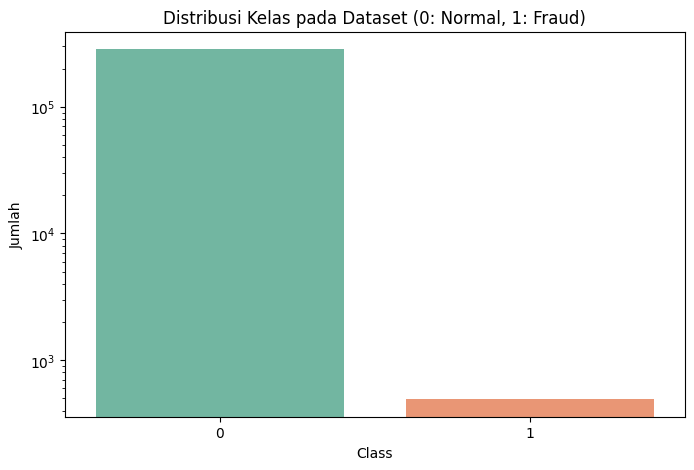

In [4]:
# Identifikasi distribusi kelas
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100

print("Jumlah data per kelas:")
print(class_counts)
print("\nPersentase data per kelas:")
print(class_percentages)

# Visualisasi distribusi kelas
plt.figure(figsize=(8, 5))
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Distribusi Kelas pada Dataset (0: Normal, 1: Fraud)')
plt.xlabel('Class')
plt.ylabel('Jumlah')
plt.yscale('log')
plt.show()

In [5]:
# Cek Missing Value
missing_values = df.isnull().sum().max()
print(f"Jumlah maksimal missing value pada kolom: {missing_values}")

#Cek Data Duplikat
total_duplicates = df.duplicated().sum()
print(f"Jumlah baris duplikat sebelum dibersihkan: {total_duplicates}")

Jumlah maksimal missing value pada kolom: 0
Jumlah baris duplikat sebelum dibersihkan: 1081


## Preprocessing

In [6]:
# Menghapus Data Duplikat
df = df.drop_duplicates()
print(f"Data duplikat berhasil dihapus. Dimensi dataset sekarang: {df.shape}")

Data duplikat berhasil dihapus. Dimensi dataset sekarang: (283726, 31)


In [7]:
# Pisahkan fitur (X) dan target (y)
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

Jumlah data latih: 226980
Jumlah data uji: 56746


In [8]:
# Oversampling dengan SMOTE agar distribusi kelas seimbang
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Distribusi kelas pada data latih SEBELUM SMOTE:")
print(y_train.value_counts())

print("\nDistribusi kelas pada data latih SESUDAH SMOTE:")
print(y_train_smote.value_counts())

Distribusi kelas pada data latih SEBELUM SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

Distribusi kelas pada data latih SESUDAH SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64


## Experimen Model

Menggunakan model **random forest** dan **booster** untuk melihat dampak class imbalace terhadap hasil

1. Model dasar (dilatih dengan data imbalanced asli).
2. Model SMOTE (dilatih dengan data yang sudah dioversampling dengan SMOTE).

In [9]:
# Inisialisasi model
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_smote = RandomForestClassifier(random_state=42, n_jobs=-1)

# Melatih model tanpa SMOTE
print("Training model tanpa SMOTE...")
rf_base.fit(X_train, y_train)

# Melatih model dengan SMOTE
print("Training model dengan SMOTE...")
rf_smote.fit(X_train_smote, y_train_smote)

Training model tanpa SMOTE...
Training model dengan SMOTE...


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## Evaluasi Model

===== Evaluasi Random Forest (Tanpa SMOTE) =====
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.92     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC Score: 0.9239444837225895
----------------------------------------


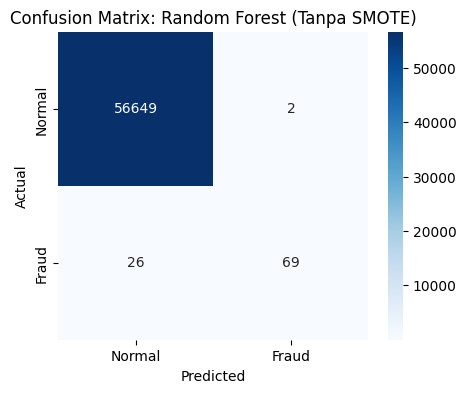

===== Evaluasi Random Forest (Dengan SMOTE) =====
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.89      0.77      0.82        95

    accuracy                           1.00     56746
   macro avg       0.94      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC Score: 0.9608973316771479
----------------------------------------


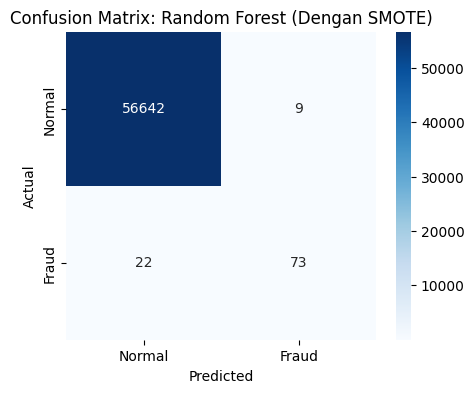

In [11]:
def evaluate_model(model, X_test, y_test, model_name):
    # Prediksi label dan probabilitas
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    print(f"===== Evaluasi {model_name} =====")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))
    print("-" * 40)
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
    plt.title(f'Confusion Matrix: {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

evaluate_model(rf_base, X_test, y_test, "Random Forest (Tanpa SMOTE)")
evaluate_model(rf_smote, X_test, y_test, "Random Forest (Dengan SMOTE)")

## Analisis

**Peningkatan Recall** 

Model dengan SMOTE berhasil meningkatkan *recall* pada kelas *fraud* (kelas 1) dari 0.73 menjadi 0.77. Pada *confusion matrix*, terlihat bahwa jumlah transaksi penipuan yang gagal dideteksi (*False Negatives*) menurun dari 26 pada model tanpa SMOTE menjadi 22 pada model dengan SMOTE. Model SMOTE mengenali lebih banyak kasus penipuan (73 *True Positives* dibandingkan 69 *True Positives* sebelumnya).


**Penurunan Precision** 

Peningkatan *recall* tersebut harus dibayar dengan penurunan *precision* dari 0.97 menjadi 0.89. Model dengan SMOTE menghasilkan lebih banyak alarm palsu (*False Positives*), meningkat dari hanya 2 kesalahan tebak menjadi 9 kesalahan tebak pada transaksi normal.


**Performa Keseluruhan (ROC-AUC & F1-Score)** 

Kemampuan model secara umum untuk membedakan kelas normal dan *fraud* meningkat secara signifikan, ditunjukkan oleh nilai ROC-AUC yang naik dari 0.9239 (tanpa SMOTE) menjadi 0.9608 (dengan SMOTE). Nilai F1-Score untuk kelas 1 sedikit menurun dari 0.83 menjadi 0.82 karena *precision* mengalami penurunan yang lebih drastis dibandingkan kenaikan *recall*.



Dalam konteks deteksi penipuan kartu kredit, model Random Forest dengan SMOTE cenderung lebih diinginkan. Mengorbankan sedikit *precision* (menghasilkan 9 alarm palsu) jauh lebih aman secara finansial dibandingkan melewatkan transaksi penipuan sebenarnya (*False Negatives*).